# Where does demand-responsive routing stop paying?

`synthetic-campaign2` tripled demand *and* cut capacity from 40 to 32 at the
same time, and the ranking inverted: fixed route went from losing to winning
on wait time, and Reordering's coverage advantage over it collapsed from
+31.4 points to +5.8. Two variables moved together, so that campaign cannot
say which one did it.

This notebook changes **one** thing. Capacity is pinned at **40** — the value
every earlier experiment used — and demand alone is swept from well below
saturation to well above it. The question it answers is not *whether* the
ranking inverts but **at what offered load**, and whether the cause is seats
or routing.

It also runs the test `synthetic-campaign2` never got to: the service-window
sweep **in the impatient regime** at a saturated load. The project's standing
recommendation is "window = patience", fitted at 1 req/min. At 3 req/min the
patient-regime data says a *tighter* window is significantly better
(W900 → W450 is −1013.8 s of wait, p=0.0010), so the rule needs re-testing
where it was actually derived.

## What it measures

1. **Stage A — the crossover.** Every policy at each offered load, both
   regimes. The output is the load at which fixed route overtakes the
   insertion policies.
2. **Stage B — the window under load.** Both families across the full window
   range, **both regimes**, at the saturated end.
3. **A saturation guard.** Offered demand against achieved throughput for
   every arm. Below that line the KPIs mean one thing and above it they mean
   another, and nothing in the earlier notebooks made it visible.

## Configuration

In [1]:
import os
from pathlib import Path

from src.experiment.store import DEFAULT_RUNS_DIR

# --- The one variable under test -----------------------------------------
# Pinned at the value every experiment before synthetic-campaign2 used, so
# that demand is the only thing moving. Change this constant alone to ask
# the capacity question later; every run is filed under it, so the store
# will simply not find the old runs and will fill in the new ones.
CAPACITY = 40

# --- The map every experiment in this project has used -------------------
# stop_density=0.5 is REQUIRED, not decorative: it makes this the 21-stop
# "campus map" every earlier result used. The generator defaults to 0.15,
# which on this seed gives 6 stops -- a map so easy that plain fixed route
# serves 100% and every comparison flattens into noise.
MAP = dict(n_seeds=17, bounds=(0.0, 0.0, 2000.0, 2000.0), seed=42,
           stop_density=0.5)

# --- Where runs are filed ------------------------------------------------
# Overridable so a smoke test can write somewhere disposable instead of the
# shared store -- which matters when another machine is filing a campaign
# into it at the same time.
RUNS = Path(os.environ.get("AUTOBUS_RUNS_DIR", DEFAULT_RUNS_DIR))

# --- Smoke mode ----------------------------------------------------------
# Set AUTOBUS_SMOKE=1 to run a few seeds at the two ends of the sweep, which
# exercises every cell in minutes rather than hours.
SMOKE = os.environ.get("AUTOBUS_SMOKE") == "1"

# --- Load ----------------------------------------------------------------
# The request count is held constant so every trial carries the same demand
# volume and only its *rate* changes. max_time is generous on purpose: a
# ceiling that truncates a run looks exactly like a coverage failure, and at
# the slow end 600 requests at one per 120 s span 72,000 s before any
# queueing.
MAX_REQUESTS = 600
MAX_TIME = 250000.0

# --- The demand sweep ----------------------------------------------------
# 20 s is synthetic-campaign2's saturated setting (3.00 req/min). 60 s is
# the setting every earlier campaign used -- and note it is *already*
# marginally saturated at this request count: campaign 1 achieved 0.86-0.90
# req/min against 1.00 offered. So the sweep has to reach past it to find an
# unsaturated point at all, which is why it runs out to 120 s.
# Bracketed against the existing capacity-40 sweep, which shows the drain
# ratio (below) running 1.30 at 2.00 req/min down to 1.00 at 0.20 -- so the
# bus is genuinely comfortable only below about 0.5/min, and the interesting
# ground is 3.00 down to 0.67 where mean seat occupancy falls from ~60% to
# ~13%. Going slower costs a great deal of simulated time for little: 600
# requests at one per 120 s span 72,000 s before any queueing at all.
# 2026-08-25: 35 s and 40 s added. The original ladder stepped straight
# from 45 s to 30 s, and the seat-occupancy guard shows that single step
# crossing the whole threshold -- 58.6% to 82.0% impatient, 76.2% to 88.6%
# patient. The ~60% line the scope condition is stated on therefore fell
# inside a gap, and where the ranking actually turns could only be named
# as "somewhere between 1.33 and 2.00 req/min". These two rungs (1.50 and
# 1.71 req/min) put three measured points inside it instead.
INTERVALS = [20.0, 25.0, 30.0, 35.0, 40.0, 45.0, 60.0, 90.0]

# The saturated end, where stage B asks its question.
SATURATED_INTERVAL = 20.0

# --- The two regimes -----------------------------------------------------
# patient exists to measure how fast a backlog drains; it cannot measure
# coverage, because with no patience every policy eventually serves
# everyone. impatient is where served_fraction means something.
REGIMES = {"patient": None, "impatient": 900.0}

# --- Service windows -----------------------------------------------------
WINDOWS = [450.0, 600.0, 750.0, 900.0, 1200.0, 1800.0]
DEFAULT_W = 900.0
# Stage A carries a second window as well, because pinning the window at
# 900 s while demand rises is what manufactured the apparent crossover: at
# 3.00 req/min the patient W900 arm is 1079 s worse than fixed route
# (p=6.0e-05) while W1800 is 127 s better (p=1.1e-19), same seeds, paired.
# Carrying both separates "the policy loses under load" from "this window
# loses under load".
WIDE_W = 1800.0

# --- Sample size ---------------------------------------------------------
# 30 to start. Extending is free: the store reruns only what is missing, so
# raising this and re-running fills in the gap rather than repeating work.
SEEDS = list(range(30))

N_JOBS = 8

if SMOKE:
    SEEDS = list(range(2))
    INTERVALS = [20.0, 120.0]
    WINDOWS = [450.0, 900.0]
    N_JOBS = 4

print(f"capacity {CAPACITY}, {MAX_REQUESTS} requests, seeds {len(SEEDS)}")
print(f"offered demand: "
      + ", ".join(f"{60 / i:.2f}/min" for i in INTERVALS))
print(f"runs -> {RUNS}" + ("   [SMOKE]" if SMOKE else ""))

capacity 40, 600 requests, seeds 30
offered demand: 3.00/min, 2.40/min, 2.00/min, 1.71/min, 1.50/min, 1.33/min, 1.00/min, 0.67/min
runs -> /home/danny/Desktop/האוניברסיטה הפתוחה/סדנה/autobus/results/runs


In [2]:
import time

import matplotlib.pyplot as plt
import pandas as pd

from src.algorithm.FixedRoutePolicy import FixedRoutePolicy
from src.algorithm.ReorderingInsertionPolicy import ReorderingInsertionPolicy
from src.algorithm.SkipStopFixedRoutePolicy import SkipStopFixedRoutePolicy
from src.algorithm.WindowInsertionPolicy import WindowInsertionPolicy
from src.experiment import plot_parameter_sweep, run_campaign
from src.experiment.store import load_frame
from src.map.graph import PlanarStreetGraph
from src.map.PlanarMapProvider import PlanarMapProvider

from IPython.display import Markdown, display

graph = PlanarStreetGraph.generate(**MAP)

# The part of a run's identity that cannot be read off the arguments. The map
# is described by its generation parameters because PlanarStreetGraph does not
# retain them -- leave one out and two different maps would share an identity.
WORLD = {
    "map": "planar",
    "n_seeds": MAP["n_seeds"],
    "bounds": list(MAP["bounds"]),
    "map_seed": MAP["seed"],
    "stop_density": MAP["stop_density"],
    "backend": "MockBackend",
}

BASE_TRIAL = dict(max_requests=MAX_REQUESTS, capacity=CAPACITY,
                  max_time=MAX_TIME)

print(f"map: {MAP['n_seeds']} seeds over {MAP['bounds'][2]:.0f} m, "
      f"{len(PlanarMapProvider(graph).get_stops())} stops")

map: 17 seeds over 2000 m, 21 stops


## The policies

Five of `synthetic-campaign2`'s nine arms are dropped. They are not dropped
for being *worse* — that would beg the question this notebook exists to ask —
but for carrying no information at any load tested so far:

| dropped | why, measured at 3.00 req/min |
|---|---|
| Nearest unserved | 19.1 points **below** fixed route on coverage, p=1.6e-11 |
| Marginal cost | returns byte-identical results to Nearest unserved on 51/60 patient and 56/60 impatient seeds — it is the same policy here |
| Ride bounded | 49.7% served, in the same bottom cluster, and never leads on any KPI |
| Constrained | 48.4% served, same cluster; also missing its impatient arm entirely |
| Deviated | 54.7% served, below plain fixed route's 68.2% |

What is kept is two non-responsive baselines and the two insertion families.
**Skip-stop is kept even though it is statistically inseparable from fixed
route at 3.00 req/min** (p=0.87 patient, p=0.62 impatient), because at
1.00 req/min it was 6.4 points ahead of it — so the sweep spans the range
where it does and does not matter, and that is itself a result.

Both insertion families are entered **twice**, at W900 and at W1800. A
single window cannot answer the crossover question: the window is admission
control, and a request the policy refuses does not leave in the patient
regime — it queues. So a window that is tight relative to the offered load
converts demand into backlog, and the resulting mean wait says nothing about
routing. Two windows an octave apart make that visible instead of letting it
masquerade as a policy result.

In [3]:
def window_family(windows):
    """
    Build the insertion policies at each service window.

    :param windows: Service windows in seconds.
    :return: (label, factory) pairs.
    """
    pairs = []
    for w in windows:
        pairs.append((f"Window W{w:.0f}",
                      lambda g, w=w: WindowInsertionPolicy(g, max_wait_s=w)))
        pairs.append((f"Reordering W{w:.0f}",
                      lambda g, w=w: ReorderingInsertionPolicy(
                          g, max_wait_s=w)))
    return pairs


BASELINES = [
    ("Fixed route", lambda g: FixedRoutePolicy(g)),
    ("Skip-stop", lambda g: SkipStopFixedRoutePolicy(g)),
]

CONTENDERS = window_family([DEFAULT_W, WIDE_W])

SHOOTOUT = BASELINES + CONTENDERS

print(f"{len(SHOOTOUT)} policies:")
for label, _ in SHOOTOUT:
    print(" ", label)

6 policies:
  Fixed route
  Skip-stop
  Window W900
  Reordering W900
  Window W1800
  Reordering W1800


## The saturation guard

A bus that cannot keep up turns every other number into a queueing
measurement. `synthetic-campaign2` was saturated throughout and nothing said
so: offered demand was 3.00 req/min and the best policy managed 2.38, so its
"mean wait" of 4,943 s was a backlog, not a service.

Two readings make it visible.

**Drain ratio** — how long the trial ran, over how long its arrivals lasted.
At 1.0 the bus finished as the last passenger appeared; above it a backlog
formed and had to be worked off afterwards. This is the honest test.
Comparing achieved throughput against the offered rate is *not*: throughput
is `fulfilled / sim_time`, and sim time always outlasts the arrival span, so
achieved sits below offered even when the bus is coping easily — measured
0.49 against 0.50 offered at 11% seat occupancy.

**Mean occupancy, by Little's law** — `throughput x ride time`. In
`synthetic-campaign2` every policy sat at 75–86% of 32 seats, which is what
made routing irrelevant: a full bus cannot pick anyone up. Below roughly 60%
the vehicle has room to be clever, and that is the regime where an insertion
policy can earn its detour.

In [4]:
def saturation(frame: "pd.DataFrame", capacity: int = CAPACITY):
    """
    Report offered demand against what each arm actually achieved.

    :param frame: Runs, as returned by ``load_frame``.
    :param capacity: Seats on the bus, for the occupancy column.
    :return: One row per policy, offered load and regime.
    """
    if frame.empty:
        return pd.DataFrame()
    # Patience has to be part of the grouping. The two regimes drain at
    # very different rates -- at 3.00 req/min the patient W900 arms sit at
    # 1.33 and their impatient twins at 1.12 -- so averaging them together
    # reports a middling number for both and hides whichever one is in
    # trouble.
    rows = frame.groupby(
        ["identity.trial.demand_interval_s", "identity.trial.max_wait_s",
         "identity.policy"], dropna=False
    ).agg(throughput=("kpi.throughput", "mean"),
          ride_s=("kpi.mean_ride_time", "mean"),
          fulfilled=("kpi.fulfilled_count", "mean"),
          n=("kpi.throughput", "size")).reset_index()
    rows["offered_per_min"] = 60.0 / rows["identity.trial.demand_interval_s"]
    # sim_time is recoverable from throughput, which is fulfilled per minute.
    rows["sim_s"] = rows["fulfilled"] / rows["throughput"] * 60.0
    rows["arrival_span_s"] = (MAX_REQUESTS
                              * rows["identity.trial.demand_interval_s"])
    rows["drain_ratio"] = rows["sim_s"] / rows["arrival_span_s"]
    # 1.10 is a judgement, not a constant of nature: the existing capacity-40
    # sweep sits at 1.02-1.03 where the bus is plainly comfortable and 1.26+
    # where it is plainly not.
    rows["saturated"] = rows["drain_ratio"] > 1.10
    # Little's law: mean number aboard = arrival rate x time aboard. Below
    # roughly 60% of seats the vehicle has room to be clever; at 85% it does
    # not, and no routing policy can help.
    rows["onboard"] = rows["throughput"] / 60.0 * rows["ride_s"]
    rows["seats_used"] = 100.0 * rows["onboard"] / capacity
    # A patience of NaN is the patient regime: nobody ever gives up.
    rows["regime"] = rows["identity.trial.max_wait_s"].isna().map(
        {True: "patient", False: "impatient"})
    return rows[["identity.trial.demand_interval_s", "regime",
                 "identity.policy", "offered_per_min", "drain_ratio",
                 "saturated", "seats_used", "n"]]


def this_campaign(directory=None):
    """
    Load only the runs belonging to this notebook's configuration.

    :param directory: Runs directory; defaults to ``RUNS``.
    :return: The matching runs as a frame.
    """
    frame = load_frame(directory or RUNS)
    if frame.empty:
        return frame
    return frame[
        (frame["identity.world.map_seed"] == MAP["seed"])
        & (frame["identity.trial.max_requests"] == MAX_REQUESTS)
        & (frame["identity.trial.capacity"] == CAPACITY)
    ].copy()

## Stage A — the crossover

Every policy at every offered load, in both regimes. This is the run that
turns "the ranking inverts under load" into a number.

In [5]:
def sweep(policies, intervals=None, regimes=REGIMES, **overrides):
    """
    Run one campaign per offered load and regime.

    :param policies: (label, factory) pairs.
    :param intervals: Demand intervals in seconds; defaults to ``INTERVALS``.
    :param regimes: Mapping of regime name to passenger patience.
    :param overrides: Trial parameters replacing ``BASE_TRIAL`` entries.
    :return: Mapping of (interval, regime) to CampaignResult.
    """
    results = {}
    for interval in (INTERVALS if intervals is None else intervals):
        for name, patience in regimes.items():
            trial = {**BASE_TRIAL, **overrides,
                     "demand_interval_s": interval}
            started = time.perf_counter()
            results[(interval, name)] = run_campaign(
                policies=policies, seeds=SEEDS, world=WORLD, directory=RUNS,
                graph=graph, n_jobs=N_JOBS, progress=True,
                max_wait_s=patience, **trial)
            outcome = results[(interval, name)]
            print(f"  {60 / interval:.2f}/min {name:<10} "
                  f"ran={outcome.ran:<5} skipped={outcome.skipped:<5} "
                  f"{(time.perf_counter() - started) / 60:.1f} min")
    return results


stage_a = sweep(SHOOTOUT)

campaign:   0%|          | 0/180 [00:00<?, ?it/s]

  3.00/min patient    ran=0     skipped=180   0.1 min


campaign:   0%|          | 0/180 [00:00<?, ?it/s]

  3.00/min impatient  ran=0     skipped=180   0.0 min


campaign:   0%|          | 0/180 [00:00<?, ?it/s]

  2.40/min patient    ran=0     skipped=180   0.0 min


... (22 outputs left out)

campaign:   0%|          | 0/180 [00:00<?, ?it/s]

  0.67/min patient    ran=0     skipped=180   0.1 min


campaign:   0%|          | 0/180 [00:00<?, ?it/s]

  0.67/min impatient  ran=0     skipped=180   0.1 min


### Reading stage A

In [6]:
frame_a = this_campaign()
frame_a = frame_a[frame_a["identity.policy"].isin(
    [label for label, _ in SHOOTOUT])]

guard = saturation(frame_a)
if not guard.empty:
    display(Markdown("**Saturation guard** — where `saturated` is True a "
                     "backlog formed, and the KPIs below measure how fast it "
                     "drained rather than how well anyone was served. "
                     "`seats_used` above ~60% means the bus is too full for "
                     "routing to matter."))
    display(guard.round(2))

**Saturation guard** — where `saturated` is True a backlog formed, and the KPIs below measure how fast it drained rather than how well anyone was served. `seats_used` above ~60% means the bus is too full for routing to matter.

,identity.trial.demand_interval_s,regime,identity.policy,offered_per_min,drain_ratio,saturated,seats_used,n
0,20.0,impatient,Fixed route,3.00,1.14,True,49.26,30
1,20.0,impatient,Reordering W1800,3.00,1.11,True,44.42,30
2,20.0,impatient,Reordering W900,3.00,1.12,True,58.14,30
3,20.0,impatient,Skip-stop,3.00,1.12,True,49.74,30
4,20.0,impatient,Window W1800,3.00,1.11,True,45.02,30
...,...,...,...,...,...,...,...,...
91,90.0,patient,Reordering W1800,0.67,1.02,False,8.57,30
92,90.0,patient,Reordering W900,0.67,1.02,False,10.40,30
93,90.0,patient,Skip-stop,0.67,1.02,False,15.63,30
94,90.0,patient,Window W1800,0.67,1.02,False,8.71,30


#### patient — mean_wait_time vs offered load

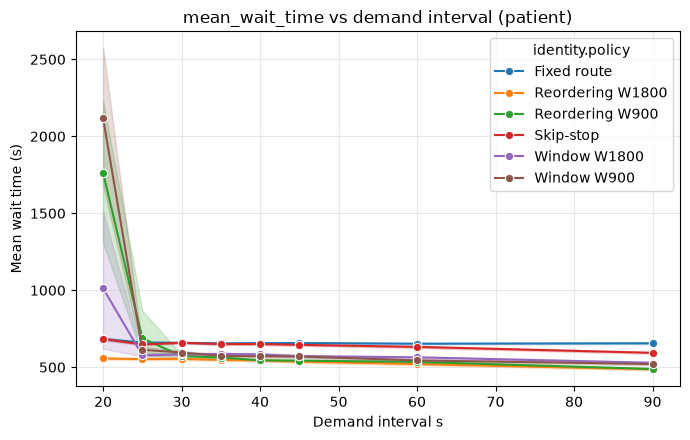

#### impatient — served_fraction vs offered load

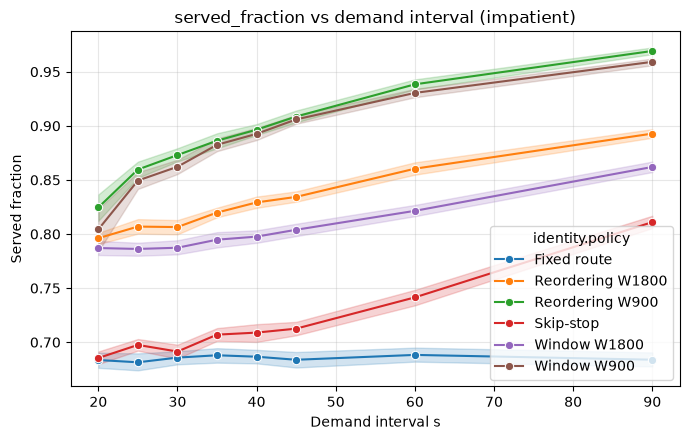

In [7]:
for regime, patience in REGIMES.items():
    subset = frame_a[frame_a["identity.trial.max_wait_s"].isna()
                     if patience is None
                     else frame_a["identity.trial.max_wait_s"] == patience]
    if subset.empty:
        continue
    # served_fraction cannot discriminate in the patient regime -- nobody
    # ever gives up -- so each regime is read on the KPI it can carry.
    metric = ("kpi.mean_wait_time" if patience is None
              else "kpi.served_fraction")
    display(Markdown(f"#### {regime} — {metric.split('.')[-1]} vs offered "
                     f"load"))
    plot_parameter_sweep(
        subset, x="identity.trial.demand_interval_s", y=metric,
        hue="identity.policy",
        title=f"{metric.split('.')[-1]} vs demand interval ({regime})")
    plt.show()

In [8]:
def crossover(frame, metric, lower_is_better):
    """
    Report where the baselines overtake the insertion policies.

    :param frame: Runs for one regime.
    :param metric: KPI column to compare.
    :param lower_is_better: Whether a smaller value wins.
    :return: A table of the best policy at each offered load.
    """
    if frame.empty:
        return pd.DataFrame()
    means = frame.groupby(
        ["identity.trial.demand_interval_s", "identity.policy"]
    )[metric].mean().reset_index()
    rows = []
    for interval, group in means.groupby("identity.trial.demand_interval_s"):
        ordered = group.sort_values(metric, ascending=lower_is_better)
        best = ordered.iloc[0]
        baseline = group[group["identity.policy"] == "Fixed route"]
        gap = (float(baseline[metric].iloc[0]) - float(best[metric])
               if not baseline.empty else float("nan"))
        rows.append({"offered_per_min": 60.0 / interval,
                     "interval_s": interval,
                     "best_policy": best["identity.policy"],
                     "best_value": round(float(best[metric]), 1),
                     "fixed_route": round(float(baseline[metric].iloc[0]), 1)
                     if not baseline.empty else float("nan"),
                     "gap_to_fixed": round(abs(gap), 1)})
    return pd.DataFrame(rows).sort_values("offered_per_min")


for regime, patience in REGIMES.items():
    subset = frame_a[frame_a["identity.trial.max_wait_s"].isna()
                     if patience is None
                     else frame_a["identity.trial.max_wait_s"] == patience]
    metric = ("kpi.mean_wait_time" if patience is None
              else "kpi.served_fraction")
    table = crossover(subset, metric, lower_is_better=patience is None)
    if not table.empty:
        display(Markdown(f"**{regime} — who wins at each load** "
                         f"({metric.split('.')[-1]})"))
        display(table)

**patient — who wins at each load** (mean_wait_time)

,offered_per_min,interval_s,best_policy,best_value,fixed_route,gap_to_fixed
7,0.666667,90.0,Reordering W1800,486.7,655.5,168.9
6,1.000000,60.0,Reordering W1800,520.5,652.9,132.5
5,1.333333,45.0,Reordering W1800,536.6,657.1,120.5
4,1.500000,40.0,Reordering W1800,544.4,656.6,112.2
3,1.714286,35.0,Reordering W1800,547.8,655.0,107.2
2,2.000000,30.0,Reordering W1800,554.3,658.9,104.6
1,2.400000,25.0,Reordering W1800,553.1,660.2,107.1
0,3.000000,20.0,Reordering W1800,556.7,683.6,126.9


**impatient — who wins at each load** (served_fraction)

,offered_per_min,interval_s,best_policy,best_value,fixed_route,gap_to_fixed
7,0.666667,90.0,Reordering W900,1.0,0.7,0.3
6,1.000000,60.0,Reordering W900,0.9,0.7,0.3
5,1.333333,45.0,Reordering W900,0.9,0.7,0.2
4,1.500000,40.0,Reordering W900,0.9,0.7,0.2
3,1.714286,35.0,Reordering W900,0.9,0.7,0.2
2,2.000000,30.0,Reordering W900,0.9,0.7,0.2
1,2.400000,25.0,Reordering W900,0.9,0.7,0.2
0,3.000000,20.0,Reordering W900,0.8,0.7,0.1


## Stage B — the service window under load

`synthetic-campaign2` ran this sweep in the patient regime only, and only to
8–11 of its 60 seeds. The impatient arm is the one that matters, because
"window = patience" is a claim about what the policy promises a passenger who
will give up — and it has never been tested above 1 req/min.

In [9]:
stage_b = sweep(window_family(WINDOWS),
                intervals=[SATURATED_INTERVAL])

campaign:   0%|          | 0/360 [00:00<?, ?it/s]

  3.00/min patient    ran=0     skipped=360   0.1 min


campaign:   0%|          | 0/360 [00:00<?, ?it/s]

  3.00/min impatient  ran=0     skipped=360   0.1 min


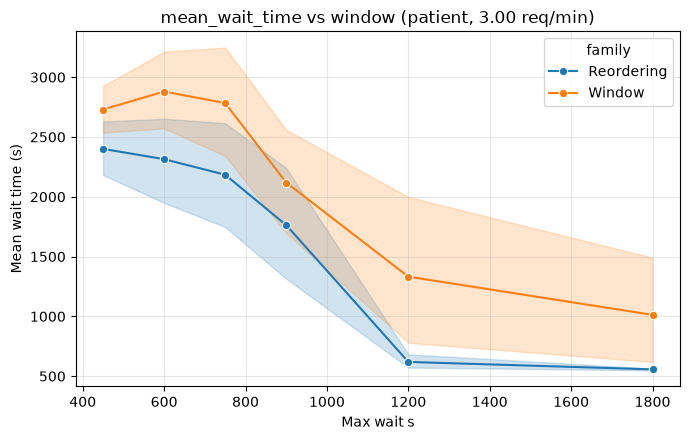

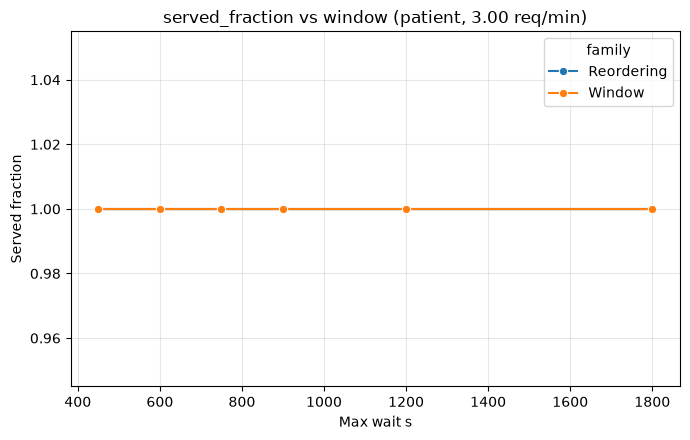

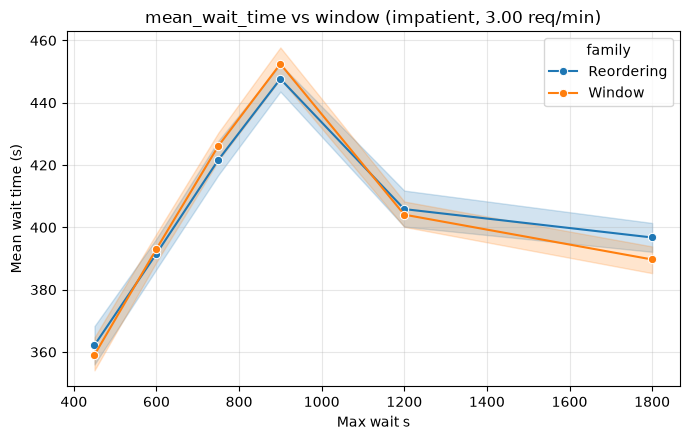

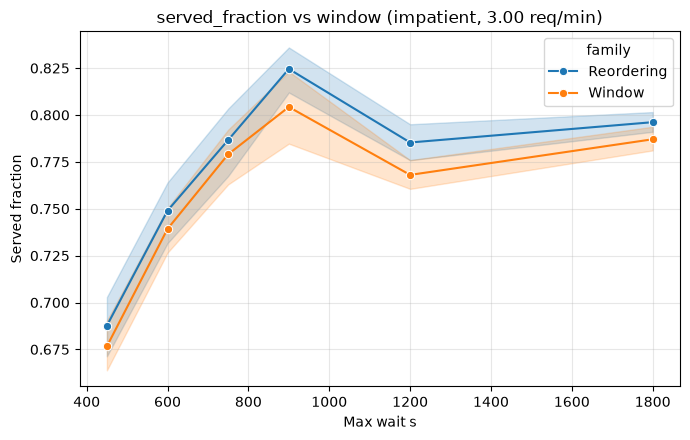

In [10]:
frame_b = this_campaign()
frame_b = frame_b[
    (frame_b["identity.trial.demand_interval_s"] == SATURATED_INTERVAL)
    & frame_b["identity.policy_params.max_wait_s"].notna()
].copy()
frame_b["family"] = frame_b["identity.policy_class"].str.replace(
    "InsertionPolicy", "", regex=False)

for regime, patience in REGIMES.items():
    subset = frame_b[frame_b["identity.trial.max_wait_s"].isna()
                     if patience is None
                     else frame_b["identity.trial.max_wait_s"] == patience]
    if subset.empty:
        continue
    for metric in ("kpi.mean_wait_time", "kpi.served_fraction"):
        plot_parameter_sweep(
            subset, x="identity.policy_params.max_wait_s", y=metric,
            hue="family",
            title=f"{metric.split('.')[-1]} vs window "
                  f"({regime}, {60 / SATURATED_INTERVAL:.2f} req/min)")
        plt.show()

In [11]:
# Does "window = patience" hold at this load? The impatient regime promises
# 900 s; if the rule holds, W900 is the best window in that panel.
impatient = frame_b[frame_b["identity.trial.max_wait_s"] == 900.0]
if impatient.empty:
    display(Markdown("_Stage B's impatient arm has not run yet._"))
else:
    best = impatient.groupby(
        ["family", "identity.policy_params.max_wait_s"]
    )["kpi.served_fraction"].mean().reset_index()
    for family, group in best.groupby("family"):
        ordered = group.sort_values("kpi.served_fraction", ascending=False)
        top = ordered.iloc[0]
        verdict = ("holds" if top["identity.policy_params.max_wait_s"] == 900.0
                   else "DOES NOT hold")
        display(Markdown(
            f"**{family}**: best window is "
            f"{top['identity.policy_params.max_wait_s']:.0f} s at "
            f"{100 * top['kpi.served_fraction']:.1f}% served — "
            f"\"window = patience\" **{verdict}** here."))
        display(ordered.round(4))

**Reordering**: best window is 900 s at 82.5% served — "window = patience" **holds** here.

,family,identity.policy_params.max_wait_s,kpi.served_fraction
3,Reordering,900.0,0.8246
5,Reordering,1800.0,0.7962
2,Reordering,750.0,0.7867
4,Reordering,1200.0,0.7853
1,Reordering,600.0,0.7490
0,Reordering,450.0,0.6877


**Window**: best window is 900 s at 80.4% served — "window = patience" **holds** here.

,family,identity.policy_params.max_wait_s,kpi.served_fraction
9,Window,900.0,0.8043
11,Window,1800.0,0.7871
8,Window,750.0,0.7791
10,Window,1200.0,0.7681
7,Window,600.0,0.7393
6,Window,450.0,0.6767


## Did we meet the statistical bar?

In [12]:
import math


def within_bar(frame, metric, bar=0.05):
    """
    Report which arms have a tight enough mean to trust.

    :param frame: Runs to check.
    :param metric: KPI column.
    :param bar: Half-width of the 95% interval, as a fraction of the mean.
    :return: One row per arm with its relative half-width.
    """
    rows = []
    grouped = frame.groupby(["identity.trial.demand_interval_s",
                             "identity.trial.max_wait_s", "identity.policy"],
                            dropna=False)[metric]
    for key, values in grouped:
        clean = values.dropna()
        if len(clean) < 2 or clean.mean() == 0:
            continue
        half = 1.96 * clean.std(ddof=1) / math.sqrt(len(clean))
        rows.append({"interval_s": key[0], "patience": key[1],
                     "policy": key[2], "n": len(clean),
                     "mean": round(clean.mean(), 1),
                     "rel_half_width": round(half / abs(clean.mean()), 3),
                     "meets_bar": half / abs(clean.mean()) <= bar})
    return pd.DataFrame(rows).sort_values("rel_half_width", ascending=False)


bar_a = within_bar(frame_a, "kpi.mean_wait_time")
if not bar_a.empty:
    missed = bar_a[~bar_a["meets_bar"]]
    display(Markdown(f"**{len(missed)} of {len(bar_a)} arms miss the 5% bar "
                     f"on mean wait.** Raise `SEEDS` and re-run; the store "
                     f"fills in only what is missing."))
    display(missed.head(20))

**4 of 96 arms miss the 5% bar on mean wait.** Raise `SEEDS` and re-run; the store fills in only what is missing.

,interval_s,patience,policy,n,mean,rel_half_width,meets_bar
10,20.0,NaN,Window W1800,30,1012.6,0.446,False
8,20.0,NaN,Reordering W900,30,1762.9,0.256,False
20,25.0,NaN,Reordering W900,30,688.6,0.225,False
11,20.0,NaN,Window W900,30,2118.7,0.215,False


## What is now in the store

In [13]:
inventory = this_campaign()
if inventory.empty:
    display(Markdown("_Nothing recorded yet._"))
else:
    summary = inventory.groupby(
        ["identity.trial.demand_interval_s", "identity.trial.max_wait_s",
         "identity.policy"], dropna=False).size().reset_index(name="seeds")
    print(f"{len(inventory)} runs at capacity {CAPACITY}")
    display(summary)

3360 runs at capacity 40


,identity.trial.demand_interval_s,identity.trial.max_wait_s,identity.policy,seeds
0,20.0,900.0,Fixed route,30
1,20.0,900.0,Reordering W1200,30
2,20.0,900.0,Reordering W1800,30
3,20.0,900.0,Reordering W450,30
4,20.0,900.0,Reordering W600,30
...,...,...,...,...
107,90.0,NaN,Reordering W1800,30
108,90.0,NaN,Reordering W900,30
109,90.0,NaN,Skip-stop,30
110,90.0,NaN,Window W1800,30
